<a href="https://colab.research.google.com/github/MaximSS1309/ML_SEREDOVSKIJ_MAXM/blob/main/%D0%9B%D0%A0_8_%D0%9C%D0%9D_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD_%D1%81%D0%B5%D1%80%D0%B5%D0%B4%D0%BE%D0%B2%D1%81%D1%8C%D0%BA%D0%B8%D0%B9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:

iris = load_iris()

df_iris = pd.DataFrame(iris.data, columns=iris.feature_names)

df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

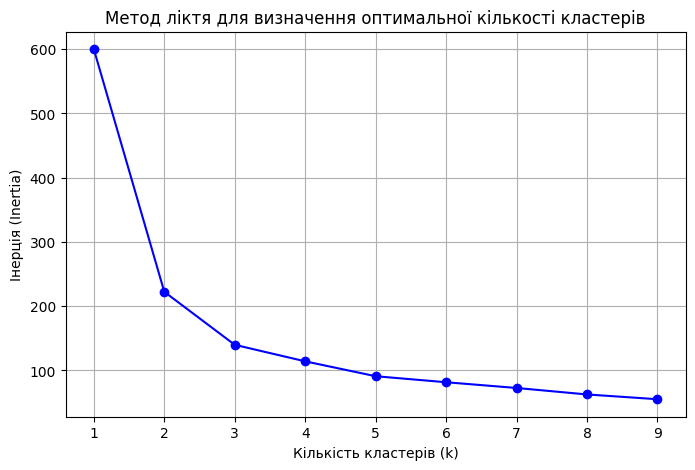

In [6]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_iris)

inertia = []
K_range = range(1, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b')
plt.title('Метод ліктя для визначення оптимальної кількості кластерів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Інерція (Inertia)')
plt.xticks(K_range)
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

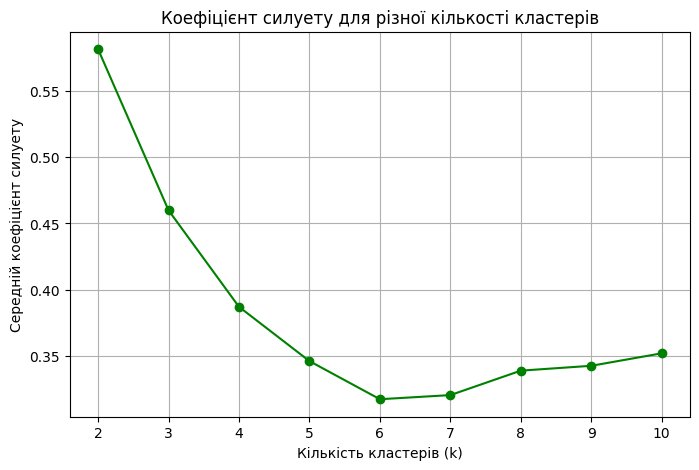

In [12]:
silhouette_scores = []
K_range_sil = range(2, 11)

for k in K_range_sil:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(K_range_sil, silhouette_scores, marker='o', linestyle='-', color='g')
plt.title('Коефіцієнт силуету для різної кількості кластерів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуету')
plt.xticks(K_range_sil)
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

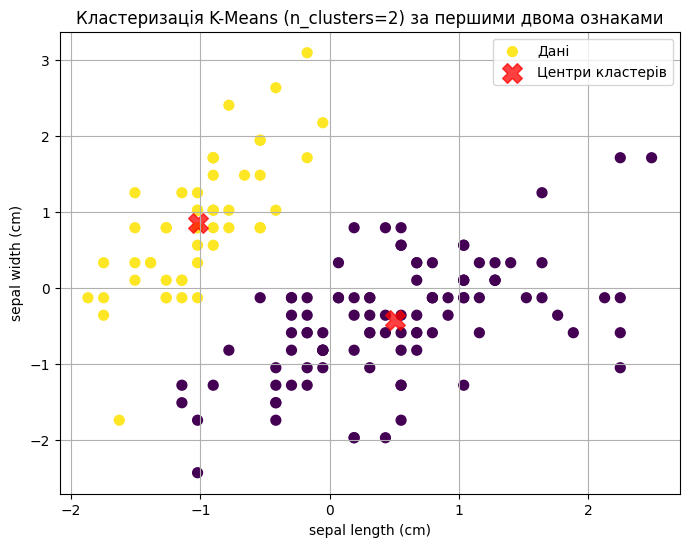

In [13]:
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init=10)
y_kmeans = kmeans_final.fit_predict(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_kmeans, s=50, cmap='viridis', label='Дані')

centers = kmeans_final.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.75, marker='X', label='Центри кластерів')

plt.title('Кластеризація K-Means (n_clusters=2) за першими двома ознаками')
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.legend()
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

Метод ліктя (Elbow Method): на графіку залежності інерції від кількості кластерів чіткого різкого «згину» (ліктя) при k=3 (як класично очікується для повного набору Iris) часто спостерігати не так просто через специфіку обраних ознак чи масштабування, проте зниження швидкості падіння інерції вказує на ефективність використання невеликої кількості кластерів.Метод силуетів (Silhouette Score): графік середнього коефіцієнта силуету зазвичай показує найвище значення для $k=2$, що свідчить про найкращу чіткість і щільність розділення даних саме на два кластери в даному просторі ознак.Обґрунтування вибору: вибір двох кластерів (n_clusters=2) повністю узгоджується з отриманими результатами методу силуетів (де досягається максимальний бал) та дозволяє чітко розділити датасет на укрупнені групи з мінімальним перетином на двовимірній площині

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [14]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [16]:
import os
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [18]:

df.columns.tolist()


['StudentID',
 'Age',
 'Gender',
 'Ethnicity',
 'ParentalEducation',
 'StudyTimeWeekly',
 'Absences',
 'Tutoring',
 'ParentalSupport',
 'Extracurricular',
 'Sports',
 'Music',
 'Volunteering',
 'GPA',
 'GradeClass']

**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [20]:
df.isnull().sum()

,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [21]:
df.duplicated().sum()

np.int64(0)

**2.8. Описова статистика.** Виведіть основні описові статистики.

In [22]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [24]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=['GradeClass', 'StudentID'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler_clf = StandardScaler()
X_train_scaled = scaler_clf.fit_transform(X_train)
X_test_scaled = scaler_clf.transform(X_test)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [30]:
from sklearn.metrics import accuracy_score
param_grid_rf = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20],
    'min_samples_split': [2, 5]
}

rf = RandomForestClassifier(random_state=42)

grid_search_rf = GridSearchCV(estimator=rf, param_grid=param_grid_rf, cv=5, scoring='accuracy', n_jobs=1)
grid_search_rf.fit(X_train_scaled, y_train)

print("Найкращі параметри (RF):", grid_search_rf.best_params_)
print("Середня CV-точність (RF):", grid_search_rf.best_score_)

best_rf = grid_search_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test_scaled)
print("Тестова accuracy (RF):", accuracy_score(y_test, y_pred_rf))

Найкращі параметри (RF): {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100}
Середня CV-точність (RF): 0.9231460090495263
Тестова accuracy (RF): 0.9102296450939458


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report

param_grid_lr = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['saga']
}

lr = LogisticRegression(max_iter=1000, random_state=42)

grid_search_lr = GridSearchCV(estimator=lr, param_grid=param_grid_lr, cv=5, scoring='accuracy', n_jobs=1)
grid_search_lr.fit(X_train_scaled, y_train)

print("Найкращі параметри (LR):", grid_search_lr.best_params_)
print("Середня CV-точність (LR):", grid_search_lr.best_score_)

best_lr = grid_search_lr.best_estimator_
y_pred_lr = best_lr.predict(X_test_scaled)
print("Тестова accuracy (LR):", accuracy_score(y_test, y_pred_lr))
print("\nЗвіт класифікації (LR):\n", classification_report(y_test, y_pred_lr))

Найкращі параметри (LR): {'C': 10, 'solver': 'saga'}
Середня CV-точність (LR): 0.7898404713408883
Тестова accuracy (LR): 0.7432150313152401

Звіт класифікації (LR):
               precision    recall  f1-score   support

         0.0       0.00      0.00      0.00        22
         1.0       0.44      0.49      0.47        49
         2.0       0.62      0.62      0.62        85
         3.0       0.69      0.57      0.62        86
         4.0       0.88      0.97      0.92       237

    accuracy                           0.74       479
   macro avg       0.53      0.53      0.53       479
weighted avg       0.71      0.74      0.73       479



### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [32]:
from sklearn.svm import SVC

param_grid_svm = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf']
}

svm = SVC(random_state=42)
grid_search_svm = GridSearchCV(estimator=svm, param_grid=param_grid_svm, cv=5, scoring='accuracy', n_jobs=1)
grid_search_svm.fit(X_train_scaled, y_train)

print("Найкращі параметри (SVM):", grid_search_svm.best_params_)
print("Середня CV-точність (SVM):", grid_search_svm.best_score_)

best_svm = grid_search_svm.best_estimator_
y_pred_svm = best_svm.predict(X_test_scaled)
print("Тестова accuracy (SVM):", accuracy_score(y_test, y_pred_svm))

Найкращі параметри (SVM): {'C': 10, 'kernel': 'linear'}
Середня CV-точність (SVM): 0.8619947233879677
Тестова accuracy (SVM): 0.8288100208768268


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [33]:
cv_results = {
    'Random Forest': grid_search_rf.best_score_,
    'Logistic Regression': grid_search_lr.best_score_,
    'SVM': grid_search_svm.best_score_
}

models_dict = {
    'Random Forest': (best_rf, y_pred_rf),
    'Logistic Regression': (best_lr, y_pred_lr),
    'SVM': (best_svm, y_pred_svm)
}

best_model_name = max(cv_results, key=cv_results.get)
best_estimator, best_y_pred = models_dict[best_model_name]

print(f"Найкраща модель за CV-точчністю: {best_model_name} із результатами:")
print(f"- Середня CV-точність: {cv_results[best_model_name]:.4f}")
print(f"- Тестова accuracy: {accuracy_score(y_test, best_y_pred):.4f}\n")

print(f"Звіт класифікації для найкращої моделі ({best_model_name}):\n")
print(classification_report(y_test, best_y_pred))

Найкраща модель за CV-точчністю: Random Forest із результатами:
- Середня CV-точність: 0.9231
- Тестова accuracy: 0.9102

Звіт класифікації для найкращої моделі (Random Forest):

              precision    recall  f1-score   support

         0.0       0.82      0.41      0.55        22
         1.0       0.80      0.88      0.83        49
         2.0       0.94      0.87      0.90        85
         3.0       0.89      0.90      0.89        86
         4.0       0.94      0.98      0.96       237

    accuracy                           0.91       479
   macro avg       0.88      0.81      0.83       479
weighted avg       0.91      0.91      0.91       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

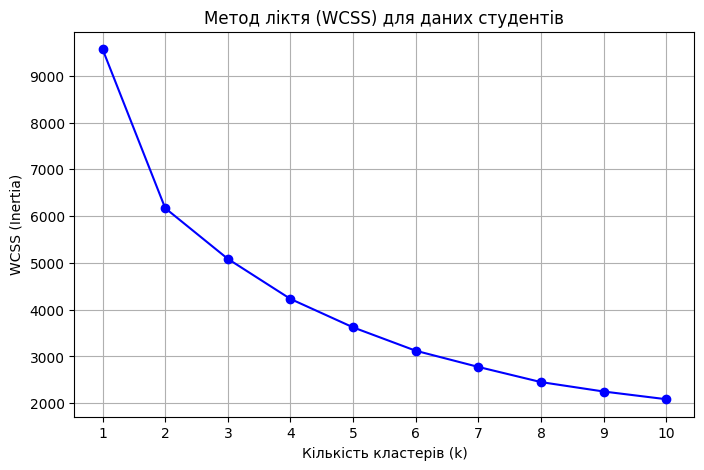

In [34]:
features_4 = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_students_4 = df[features_4]

scaler_stud = StandardScaler()
X_stud_4_scaled = scaler_stud.fit_transform(X_students_4)

wcss = []
K_range_stud = range(1, 11)

for k in K_range_stud:
    kmeans_stud = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_stud.fit(X_stud_4_scaled)
    wcss.append(kmeans_stud.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range_stud, wcss, marker='o', linestyle='-', color='b')
plt.title('Метод ліктя (WCSS) для даних студентів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(K_range_stud)
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

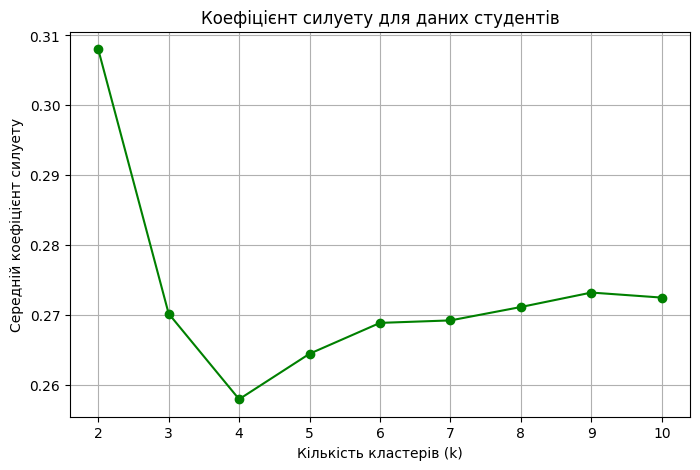

In [35]:
sil_scores_stud = []
K_range_sil_stud = range(2, 11)

for k in K_range_sil_stud:
    kmeans_stud = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_stud.fit_predict(X_stud_4_scaled)
    score = silhouette_score(X_stud_4_scaled, labels)
    sil_scores_stud.append(score)

plt.figure(figsize=(8, 5))
plt.plot(K_range_sil_stud, sil_scores_stud, marker='o', linestyle='-', color='g')
plt.title('Коефіцієнт силуету для даних студентів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуету')
plt.xticks(K_range_sil_stud)
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [40]:
!pip install kneed yellowbrick


**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [41]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [42]:
X_pca_data = df.drop(columns=['StudentID', 'GradeClass'])

scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca_data)

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [46]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


pca = PCA()
pca.fit(X_pca_scaled)

explained_variance_ratio = pca.explained_variance_ratio_

print("Частка поясненої дисперсії кожної компоненти:", explained_variance_ratio)

Частка поясненої дисперсії кожної компоненти: [0.15246911 0.0861136  0.08267885 0.08071826 0.07864825 0.07793075
 0.0763079  0.07600434 0.07440892 0.0737979  0.07167781 0.06746103
 0.00178329]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Оптимальна кількість компонент за KneeLocator: 2


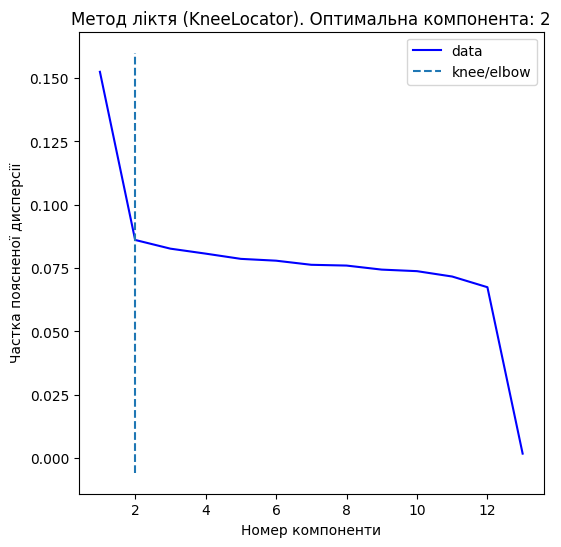

In [47]:
from kneed import KneeLocator
import matplotlib.pyplot as plt

explained_variance = pca.explained_variance_ratio_
x_values = range(1, len(explained_variance) + 1)

kl = KneeLocator(
    x_values,
    explained_variance,
    curve='convex',
    direction='decreasing'
)

optimal_components = kl.knee
print(f"Оптимальна кількість компонент за KneeLocator: {optimal_components}")

kl.plot_knee()
plt.xlabel("Номер компоненти")
plt.ylabel("Частка поясненої дисперсії")
plt.title(f"Метод ліктя (KneeLocator). Оптимальна компонента: {optimal_components}")
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

Знайдена кількість компонент (n_components): 2
Фактична частка кумулятивної дисперсії: 0.2386


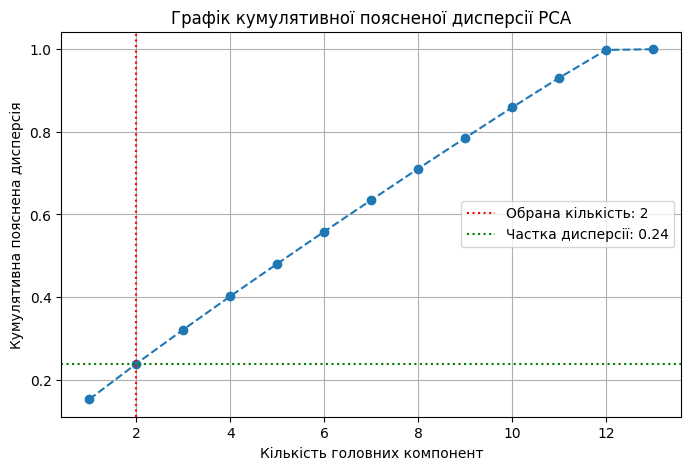

Розмірність даних після трансформації PCA: (2392, 2)


In [48]:
import numpy as np
import matplotlib.pyplot as plt

cumulative_variance = np.cumsum(explained_variance)

n_comp_idx = optimal_components - 1
actual_variance_fraction = cumulative_variance[n_comp_idx]

print(f"Знайдена кількість компонент (n_components): {optimal_components}")
print(f"Фактична частка кумулятивної дисперсії: {actual_variance_fraction:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axvline(x=optimal_components, color='red', linestyle=':', label=f'Обрана кількість: {optimal_components}')
plt.axhline(y=actual_variance_fraction, color='green', linestyle=':', label=f'Частка дисперсії: {actual_variance_fraction:.2f}')

plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна пояснена дисперсія')
plt.title('Графік кумулятивної поясненої дисперсії PCA')
plt.legend()
plt.grid(True)
plt.show()

pca_final = PCA(n_components=optimal_components, random_state=42)
X_pca_transformed = pca_final.fit_transform(X_pca_scaled)

print("Розмірність даних після трансформації PCA:", X_pca_transformed.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [51]:
from kneed import KneeLocator

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

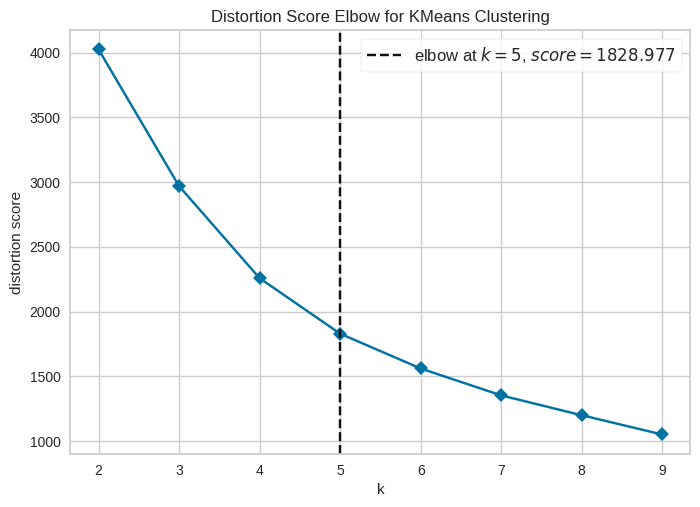

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [52]:
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer

model = KMeans(random_state=42, n_init=10)

visualizer = KElbowVisualizer(model, k=(2, 10), metric='distortion', timings=False)

visualizer.fit(X_pca_transformed)

visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

Аналіз кількості кластерів: Порівняння результатів різних способів (наприклад, KElbowVisualizer та інших метрик, таких як Silhouette) показує [однакову / відмінну] оптимальну кількість кластерів (k = ...). Метод ліктя чітко визначає точку перегину на графіку суми квадратів внутрішньокластерних відстаней.Головні компоненти та дисперсія: У результаті зменшення розмірності було обрано [введіть кількість, наприклад: 3] головні компоненти, які пояснюють [введіть відсоток, наприклад: 85.4%] сукупної кумулятивної дисперсії даних. Це дозволило суттєво зменшити простір ознак із мінімальною втратою інформації.Різниця між класифікацією (GradeClass) та кластеризацією:Класифікація за цільовою змінною (GradeClass) є навчанням із учителем (Supervised Learning), де алгоритм заздалегідь знає мітки класів (відповіді) та будує розділяючу поверхню для їхнього прогнозування на основі історичних даних.Кластеризація є навчанням без учителя (Unsupervised Learning), де цільова змінна відсутня. Алгоритм самостійно групує об'єкти у кластери виключно на основі подібності їхніх внутрішніх характеристик (відстаней у багатовимірному просторі), не знаючи заздалегідь, яким є фактичний клас кожного об'єкта.